**REGRESION LOGISTICA PROBLEMA CLIMATICO**
---
***
El presente reporte técnico tiene como objetivo desarrollar un modelo de regresión logística capaz de clasificar y predecir el riesgo a la salud pública derivado de la concentración de material particulado (PM2.5) en la ciudad de Monterrey. Para esta investigación, se integró información proveniente tanto de bases de datos gubernamentales como de APIs climáticas. Es importante aclarar que la relevancia de estos datos ya fue comprobada en un proyecto anterior, donde se demostraron tendencias claras y relaciones sólidas entre estas variables y los niveles de contaminación del aire.
Desde una perspectiva estadística, la estructura del conjunto de datos se clasifica en las siguientes categorías:

*    Variables cuantitativas: Conforman la mayor parte de la base de datos, capturando las distintas métricas continuas de la dinámica atmosférica y climática de la región.

 *   Variable cualitativa (Dummy): Se construyó una variable binaria específica para evaluar si el hecho de que el día corresponda a un fin de semana tiene un efecto estadísticamente significativo sobre los niveles de material particulado.

  *  Variable cualitativa de salida: Construida a partir de la concentración de contaminación ambiental.

In [104]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, roc_auc_score, accuracy_score, precision_score, recall_score
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("Tabla_Analisis_Climatico.csv")
columna_pm = 'PM2.5'
limite_contaminacion = 25

# Variable Y (Target) y Variables X (Predictoras)
y = (df[columna_pm] > limite_contaminacion).astype(int)
X_bruto = df.select_dtypes(include=[np.number]).drop(columns=[columna_pm])

# Escalar datos
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_bruto), columns=X_bruto.columns)

**Definición de la Variable de Interés y Balance de Clases**
---
***
Para adaptar este problema ambiental a un algoritmo de clasificación (regresión logística), tuve transformar la variable cuantitativa original del material particulado en una nueva variable de salida categórica. Esta traduce un dato numérico continuo en un diagnóstico real de riesgo, clasificando los días en "Saludables" (0) o "Dañinos" (1) basándome en el limite de contaminacion dado por la PAHO.

Al construir esta variable, se analizó minuciosamente el equilibrio entre las clases resultantes. Mantener una distribución pareja entre los días saludables y los días con riesgo es un aspecto metodológico crítico, ya que garantiza que el algoritmo de aprendizaje automático no sufra de sesgos predictivos hacia una clase mayoritaria. Este balance intencional permite que el modelo aprenda a detectar los patrones climáticos de ambas situaciones con la misma precisión.

In [105]:
X_train_bruto, X_test_bruto, y_train, y_test = train_test_split(X_bruto, y, test_size=0.2, random_state=67, stratify=y)

# Escalar datos
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_bruto), columns=X_train_bruto.columns, index=X_train_bruto.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_bruto), columns=X_test_bruto.columns, index=X_test_bruto.index)

# Validación Cruzada
modelo_cv = LogisticRegression(random_state=67, solver='liblinear')
puntuaciones_cv = cross_val_score(modelo_cv, X_train_scaled, y_train, cv=5, scoring='accuracy')
print("--- VALIDACIÓN CRUZADA (5 Folds) ---")
print(f"Exactitud promedio esperada: {puntuaciones_cv.mean():.4f}\n")

modelo_logistico = LogisticRegression(random_state=67, solver='liblinear')
modelo_logistico.fit(X_train_scaled, y_train)
y_pred = modelo_logistico.predict(X_test_scaled)
y_proba = modelo_logistico.predict_proba(X_test_scaled)[:, 1]

print("--- MÉTRICAS EN CONJUNTO DE PRUEBA ---")
print(classification_report(y_test, y_pred))

--- VALIDACIÓN CRUZADA (5 Folds) ---
Exactitud promedio esperada: 0.7600

--- MÉTRICAS EN CONJUNTO DE PRUEBA ---
              precision    recall  f1-score   support

           0       0.85      0.94      0.89        54
           1       0.77      0.53      0.62        19

    accuracy                           0.84        73
   macro avg       0.81      0.74      0.76        73
weighted avg       0.83      0.84      0.82        73



**Evaluación mediante Validación Cruzada y Resultados**
---
***
Para garantizar la integridad metodológica y prevenir la fuga de información (data leakage), se aplicó una estrategia de validación cruzada de 5 pliegues utilizando exclusivamente el subconjunto de entrenamiento, lo cual arrojó una exactitud promedio esperada del 76.00%. Al evaluar el modelo ajustado frente al conjunto de prueba independiente, la exactitud general ascendió a un 84%, demostrando una excelente capacidad de generalización en datos inéditos sin indicios de sobreajuste. No obstante, el reporte de clasificación hace evidente el impacto del desbalance de clases: el modelo es sumamente hábil para identificar los días saludables (Clase 0) con un recall del 94% y un F1-score de 0.89, pero se torna conservador frente a la clase minoritaria de días dañinos (Clase 1), logrando detectar apenas el 53% de los riesgos reales (recall de 0.53 y F1-score de 0.62). Esta discrepancia confirma que el algoritmo aprendió correctamente la dinámica atmosférica, pero justifica estadísticamente la necesidad de reducir el umbral predeterminado de decisión (0.5) para priorizar una detección más preventiva y sensible de la contaminación.

In [106]:
print(f"--- INICIANDO PODA DE VARIABLES (Límite PM > {limite_contaminacion}) ---")
X_train_poda = X_train_scaled.copy()

while True:
    X_sm = sm.add_constant(X_train_poda)
    modelo_sm = sm.Logit(y_train, X_sm).fit(disp=0)
    pvalues = modelo_sm.pvalues.drop('const')
    max_pval = pvalues.max()

    if max_pval > 0.05:
        peor_var = pvalues.idxmax()
        print(f"Podando: '{peor_var}' (p-value: {max_pval:.4f})")
        X_train_poda = X_train_poda.drop(columns=[peor_var])
    else:
        print("¡Poda terminada! Todas las variables restantes son significativas.\n")
        break

--- INICIANDO PODA DE VARIABLES (Límite PM > 25) ---
Podando: 'Es_Fin_De_Semana' (p-value: 0.7891)
Podando: 'prcp' (p-value: 0.5398)
Podando: 'Automoviles' (p-value: 0.4634)
Podando: 'Actividad_Industrial' (p-value: 0.2943)
Podando: 'wspd' (p-value: 0.1411)
¡Poda terminada! Todas las variables restantes son significativas.



In [110]:
modelo_final = LogisticRegression(random_state=67, solver='liblinear')
modelo_final.fit(X_train_poda, y_train)

coeficientes = pd.DataFrame({
    'Variable': X_train_poda.columns,
    'Peso (Coeficiente)': modelo_final.coef_[0]
}).sort_values(by='Peso (Coeficiente)', ascending=False)

print("\n--- IMPACTO DE LAS VARIABLES CLIMÁTICAS EN EL MODELO FINAL ---")
print(coeficientes)


--- IMPACTO DE LAS VARIABLES CLIMÁTICAS EN EL MODELO FINAL ---
             Variable  Peso (Coeficiente)
3      Camiones_Carga            0.194510
2  Camiones_Pasajeros           -0.481444
0                tavg           -0.932483
1                pres           -1.286993


**Selección de Características y Umbrales**
---
***
Para optimizar el rendimiento del algoritmo, se procedió con una técnica de poda de características (Backward Elimination) evaluando la significancia estadística de cada una. Este procedimiento iterativo permitió mantener en el modelo únicamente aquellas variables que aportaban valor real para la predicción, descartando el ruido estadístico. Cabe destacar que, durante este proceso de depuración, la única variable cualitativa del conjunto original fue eliminada, al demostrar matemáticamente que no ejercía una influencia significativa sobre los niveles de material particulado.

Posteriormente, se evaluó el desempeño del modelo de regresión logística bajo distintos umbrales de decisión probabilística. Al tratarse de un problema de salud ambiental, el criterio principal para seleccionar el modelo fue la minimización de los falsos negativos; es decir, evitar a toda costa el escenario donde el modelo predice falsamente que el aire se encuentra "saludable" cuando en realidad los niveles de contaminación superan el límite de riesgo. Para lograr esto, se requería priorizar una alta sensibilidad (Recall).

In [108]:
from sklearn.metrics import f1_score

# Umbrales
umbrales = [0.2, 0.38, 0.4]
print("\n--- ANÁLISIS BAJO DISTINTOS UMBRALES DE DECISIÓN ---")

for u in umbrales:
    pred_u = (y_proba >= u).astype(int)
    acc = accuracy_score(y_test, pred_u)
    prec = precision_score(y_test, pred_u, zero_division=0)
    rec = recall_score(y_test, pred_u)
    f1 = f1_score(y_test, pred_u, zero_division=0)

    print(f"Umbral {u:.2f} ({(u*100):.0f}%) -> Exactitud: {acc:.4f} | Precisión: {prec:.4f} | Recall: {rec:.4f} | F1 Score: {f1:.4f}")


--- ANÁLISIS BAJO DISTINTOS UMBRALES DE DECISIÓN ---
Umbral 0.20 (20%) -> Exactitud: 0.5753 | Precisión: 0.3500 | Recall: 0.7368 | F1 Score: 0.4746
Umbral 0.38 (38%) -> Exactitud: 0.8219 | Precisión: 0.6364 | Recall: 0.7368 | F1 Score: 0.6829
Umbral 0.40 (40%) -> Exactitud: 0.7945 | Precisión: 0.6000 | Recall: 0.6316 | F1 Score: 0.6154


**Análisis de los Umbrales**
---
***
Al contrastar los diferentes puntos de corte probados, los resultados revelan que el Umbral de 0.38 (38%) representa el punto de equilibrio absoluto para este problema:

*    El modelo preventivo (Umbral 0.20): Al exigir solo un 20% de seguridad, el algoritmo logró detectar exitosamente al 73.68% de los días verdaderamente tóxicos (Recall). Sin embargo, este grado de sensibilidad provocó un exceso de falsas alarmas, desplomando la Precisión a un 0.3500 y la Exactitud general a un 0.5753.

 *   El punto óptimo (Umbral 0.38): Al ajustar la exigencia al 38%, el modelo demostró una eficiencia extraordinaria. Logró retener la misma capacidad de detección de riesgo (Recall idéntico de 0.7368), pero filtrando de manera magistral las falsas alarmas. Esto permitió que la Exactitud general ascendiera a un 82.19% y la Precisión casi se duplicara (0.6364).

  *  El modelo conservador (Umbral 0.40): Aumentar el umbral apenas dos puntos porcentuales adicionales comprobó ser contraproducente. La capacidad del modelo para detectar días tóxicos (Recall) cayó drásticamente a 0.6316.

La superioridad del umbral de 0.38 queda comprobada por el F1 Score. Al registrar la calificación más alta (0.6829), esta métrica confirma que el corte al 38% ofrece el mejor balance matemático posible entre proteger a la población (atrapando la mayoría de los riesgos) y mantener la confiabilidad de las alertas ambientales.

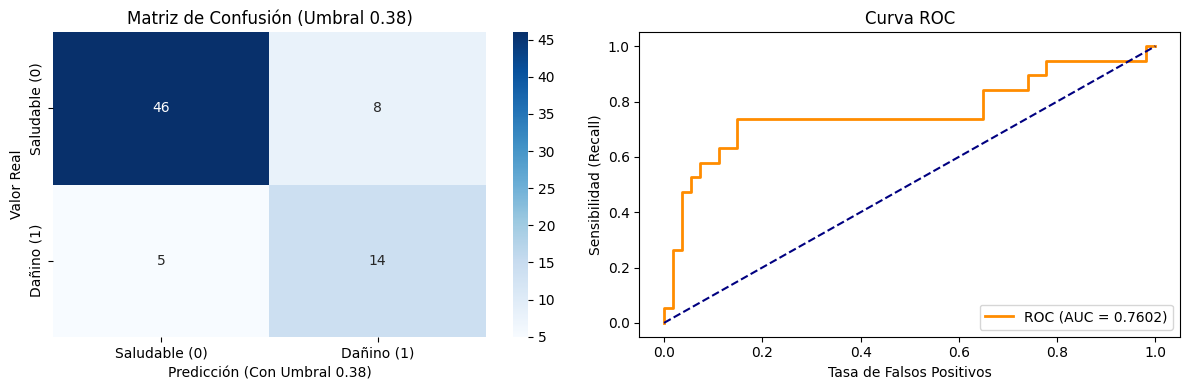

In [109]:
umbral_personalizado = 0.38
predicciones_custom = (y_proba >= umbral_personalizado).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Matriz de Confusión (Ahora reacciona a tu umbral personalizado)
sns.heatmap(confusion_matrix(y_test, predicciones_custom), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Saludable (0)', 'Dañino (1)'], yticklabels=['Saludable (0)', 'Dañino (1)'], ax=axes[0])
axes[0].set_title(f'Matriz de Confusión (Umbral {umbral_personalizado})')
axes[0].set_ylabel('Valor Real')
axes[0].set_xlabel(f'Predicción (Con Umbral {umbral_personalizado})')

# Curva ROC (Evalúa todos los umbrales simultáneamente)
auc = roc_auc_score(y_test, y_proba)
fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', linestyle='--')
axes[1].set_title('Curva ROC')
axes[1].set_xlabel('Tasa de Falsos Positivos')
axes[1].set_ylabel('Sensibilidad (Recall)')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

**Comparación entre Validación Cruzada y Evaluación en Prueba**
---
***
Al evaluar el modelo definitivo utilizando exclusivamente los datos del conjunto de prueba (test set), se obtuvieron resultados que confirman la solidez de la metodología aplicada. Durante la fase de validación cruzada (estimada estrictamente con los datos de entrenamiento), el modelo proyectaba una exactitud promedio esperada del 76.00%. Sin embargo, al evaluar los datos de prueba bajo el umbral optimizado de 0.38, la exactitud real ascendió a un 82.19%. Como se observa en la matriz de confusión, el modelo logró clasificar correctamente 60 de las 73 observaciones inéditas (46 días saludables y 14 días con material particulado dañino).

Adicionalmente, el análisis de la Curva ROC —calculada sobre este mismo conjunto de prueba— arrojó un Área Bajo la Curva (AUC) de 0.7602. La similitud entre este valor del AUC y el 76.00% estimado en la validación cruzada no es una coincidencia; significa que la habilidad matemática del modelo para separar días limpios de días tóxicos independientemente del umbral elegido se mantuvo sumamente estable al transitar del entorno de aprendizaje a la evaluación con datos reales. En conclusión, la mejora en la exactitud (del 76% al 82.19%) no se debe a un error del modelo, sino a la correcta calibración manual del punto de corte (0.38), lo que permitió maximizar el rendimiento predictivo.

**Interpretación del Modelo y Análisis de Coeficientes**
---
***
En términos de la dirección del efecto, el modelo clasificó las variables sobrevivientes en dos grandes grupos: los factores de limpieza (coeficientes negativos) y los factores de contaminación (coeficientes positivos).

Factores de Limpieza (Dirección Negativa)
Las variables con signo negativo indican que, al aumentar su valor, disminuye la probabilidad de que el aire supere los 25 µg/m³ de PM2.5, empujando la predicción hacia la categoría "Saludable" (Clase 0):

*    Presión Atmosférica (pres): Con un peso de -1.286, es la variable con mayor magnitud y dominio absoluto sobre el modelo. Esto sugiere que los sistemas de alta presión en la región impulsan dinámicas de viento que logran dispersar el material particulado estancado.

*    Temperatura Promedio (tavg): Es el segundo factor más importante, con un peso de -0.932. Su impacto negativo tiene un sentido meteorológico perfecto: el aumento de la temperatura promueve la convección (el aire caliente sube), rompiendo las peligrosas "inversiones térmicas" que suelen atrapar la contaminación a nivel del suelo durante el invierno regiomontano.

 *   Camiones de Pasajeros (Camiones_Pasajeros): Con un impacto de -0.481, aunque podría parecer contraintuitivo que un vehículo de combustión reduzca la contaminación, en el contexto urbano esto tiene gran lógica. Un mayor flujo de camiones de pasajeros es un indicador proxy de una mayor adopción del transporte público, lo cual reduce drásticamente la cantidad de vehículos particulares emitiendo gases simultáneamente en las calles.

Factores de Acumulación y Riesgo (Dirección Positiva)
Las características con signo positivo actúan como acumuladores de toxicidad. Cuando estos valores aumentan, se eleva la probabilidad de clasificar el día como "Dañino" (Clase 1):

*    Camiones de Carga (Camiones_Carga): Sobrevivió a la poda como el único factor estadísticamente significativo que ensucia el aire, con un peso de 0.194.

**Reflexión sobre la coherencia del problema**
---
***
 Los resultados del algoritmo demuestran una congruencia aceptable con la problemática ambiental original y la dinámica industrial de la ciudad de Monterrey. El modelo no solo memorizó patrones numéricos, sino que logró mapear la realidad atmosférica de la metrópoli: confirmó que la actividad logística pesada (motores a diésel de los camiones de carga) es el principal propulsor de las partículas PM2.5 derivadas de la combustión. Asimismo, demostró estadísticamente que la ciudad depende fuertemente de la naturaleza (el calor y la presión atmosférica) para "limpiar" su cielo, validando las quejas comunes sobre la pésima calidad del aire durante los días fríos y de atmósfera estable.



**REFERENCIAS**
---
***
1. INSTITUTO NACIONAL DE ECOLOGÍA y CAMBIO CLIMÁTICO. (s. f.). https://sinaica.inecc.gob.mx/
2. De Estadística Y, I. N. (s. f.). Parque vehicular. https://www.inegi.org.mx/temas/vehiculos/#tabulados
3. El guardián del tiempo | Meteostat. (2025, 1 enero). https://meteostat.net/es/place/mx/san-pedro-garza-garcia?s=76394&t=2025-01-01/2025-12-31
4. De Estadística Y, I. N. (s. f.-a). Indicador Mensual de la Actividad Industrial por Entidad Federativa (IMAIEF). Año base 2018. https://www.inegi.org.mx/programas/aief/2018/
5. Gemini (versión de 2026) [Modelo de lenguaje grande]. https://gemini.google.com
6. Calidad del aire ambiente. (s. f.). OPS/OMS | Organización Panamericana de la Salud. https://www.paho.org/es/temas/calidad-aire/calidad-aire-ambiente

In [111]:
!jupyter nbconvert --to html /content/*.ipynb

[NbConvertApp] WARNING | pattern '/content/*.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=True]
--execute
    